In [30]:
import gc
import json
import torch
import datasets
import numpy as np
import pandas as pd
import pickle as pkl
from tqdm import tqdm
from sklearn import metrics
from evaluate import load
import evaluate
from matplotlib import pyplot as plt
from utils import get_texts_for_ptype
from transformers import AutoTokenizer
from scipy.optimize import minimize_scalar
from transformers import TrainingArguments, Trainer
from transformers import AutoModelForSequenceClassification

In [6]:
metric_acc = load("accuracy", trust_remote_code=True)
metric_p = load("precision", trust_remote_code=True)
metric_r = load("recall", trust_remote_code=True)
metric_f = load("f1", trust_remote_code=True)

In [7]:
def predict(df, db=0):
    return [int(x>=db) for x in df ]

neg_pos_ratio_dict = {
    "is_rct": 5585042/489295,
    "is_sr": 5659292/121063,
    "is_casecontrol": 5628219/65790,
    "is_cohort": 5632460/78688,
    "is_guideline": 5676411/33826
}

def calc_precision(recall, specificity, neg_pos_ratio):
    return recall / (recall + neg_pos_ratio * (1 - specificity) + 1e-15)

def calc_f1(recall, precision):
    return 2*recall*precision/(recall+precision + 1e-15)

def get_scores(predictions):
    return [np.exp(p[1])/(np.exp(p[0]) + np.exp(p[1])) for p in predictions]

In [183]:
neg_to_pos_ratio=1
names_to_capital = {
    "distilbert-base-uncased": "Distill-BERT",
    "bert-base-cased": "BERT",
    "allenai": "SciBERT",
    "dmis-lab": "BioBERT",
    "microsoft": "PubMedBERT"
}

names_to_actual = {
    "distilbert-base-uncased": "distilbert-base-uncased",
    "bert-base-cased": "bert-base-cased",
    "allenai": "allenai/scibert_scivocab_uncased",
    "dmis-lab": "dmis-lab/biobert-base-cased-v1.2",
    "microsoft": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"
}

model_subfolder = {
    'allenai': 'scibert_scivocab_uncased',
    'dmis-lab': 'biobert-base-cased-v1.2',
    'microsoft': 'BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext'
}

ptypes = ['is_rct', 'is_sr', 'is_casecontrol', 'is_cohort', 'is_guideline']
model_types = ['distilbert-base-uncased', 'bert-base-cased', 'allenai', 'dmis-lab', 'microsoft']

In [103]:
# bert_outputs_labels = {}
# for ptype in ['is_rct', 'is_sr', 'is_cohort', 'is_cohort', 'is_guideline', 'is_casecontrol']:
#     X_train, X_val, X_test, y_train, y_val, y_test = get_texts_for_ptype('is_rct', inputs="titles_abstracts", neg_to_pos_ratio=neg_to_pos_ratio)
#     bert_outputs_labels[ptype] = {}
#     for model_type in ['allenai', 'bert-base-cased', 'distilbert-base-uncased', 'dmis-lab', 'microsoft']:
#         print(ptype, model_type)
#         if model_type in model_subfolder:
#             path = f'trained/{ptype}_{model_type}/{model_subfolder[model_type]}'
#         else:
#             path = f'trained/{ptype}_{model_type}'
#         model = AutoModelForSequenceClassification.from_pretrained(path)
#         tokenizer = AutoTokenizer.from_pretrained(names_to_actual[model_type], force_download=False)
#         tokenized_datasets = dataset.map(tokenize_function, batched=True)
#         test_dataset = tokenized_datasets['test'].map(tokenize_function, batched=True)
#         test_dataset = test_dataset.shuffle(seed=42)
        
#         encoded_input = tokenizer(list(X_test), return_tensors='pt', padding="max_length", truncation=True, max_length=512).to('cuda')
#         model = model.to("cuda")
#         input_ids = encoded_input['input_ids']
#         attention_mask = encoded_input['attention_mask']
#         outputs = []
#         for ii, am in zip(tqdm(input_ids), attention_mask):
#             output = model(
#                 **{
#                     'input_ids': ii.reshape((1, -1)),
#                     'attention_mask': am.reshape((1, -1))
#                 }
#             )
#             outputs.append(output[0].cpu().detach().numpy())
#         bert_outputs_labels[ptype][names_to_capital[model_type]] = {
#             'labels': y_test,
#             'outputs': outputs
#         }
#         with open('bert_output_labels.pkl', 'wb') as f:
#             pkl.dump(bert_outputs_labels, f)
            
# #         with open('bert_output_labels.pkl', 'rb') as f:
# #             bert_outputs_labels = pkl.load(f)
#         model = model.to('cpu')
#         del model
#         gc.collect()
#         torch.cuda.empty_cache()
    

19it [00:24,  1.30s/it]/home/k2141255/anaconda3/envs/study_design_classifier_bert/lib/python3.11/site-packages/tqdm/std.py:1181: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
51it [01:04,  1.28s/it]/home/k2141255/anaconda3/envs/study_design_classifier_bert/lib/python3.11/site-packages/tqdm/std.py:1181: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  for obj in iterable:
86it [01:48,  1.26s/it]
57it [01:22,  1.44s/it]
/home/k2141255/anaconda3/envs/study_design_classifier_bert/lib/python3.11/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


is_rct allenai


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

100%|████████████████████████████████████████| 8000/8000 [01:10<00:00, 113.06it/s]


...

100%|████████████████████████████████████████| 8000/8000 [01:11<00:00, 111.88it/s]


is_casecontrol microsoft


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

100%|████████████████████████████████████████| 8000/8000 [01:10<00:00, 112.91it/s]


In [77]:
bert_outputs_labels['is_rct'].keys()

dict_keys(['SciBERT', 'BERT', 'Distill-BERT', 'BioBERT', 'PubMedBERT'])

In [ ]:
# with open('bert_output_labels.pkl', 'rb') as f:
#     bert_outputs_labels = pkl.load(f)

In [104]:
y_score = bert_outputs_labels[ptype][mtype]["outputs"]
y_score

[array([[ 0.62893766, -1.2054254 ]], dtype=float32),
 array([[-1.0220478,  0.5182244]], dtype=float32),
 array([[-1.0220478,  0.5182245]], dtype=float32),
 array([[ 0.62895525, -1.2054099 ]], dtype=float32),
 array([[ 0.6289782, -1.2053857]], dtype=float32),
 array([[ 0.62895125, -1.2054108 ]], dtype=float32),
 array([[-1.0220478,  0.5182244]], dtype=float32),
 array([[ 0.6289736, -1.2053889]], dtype=float32),
 array([[-1.0220478,  0.5182245]], dtype=float32),
 array([[-1.0220476 ,  0.51822436]], dtype=float32),
 array([[ 0.62898046, -1.2053806 ]], dtype=float32),
 array([[-1.0220478,  0.5182244]], dtype=float32),
 array([[ 0.6289345, -1.2054311]], dtype=float32),
 array([[ 0.6289554, -1.2054092]], dtype=float32),
 array([[ 0.62903285, -1.2053293 ]], dtype=float32),
 array([[ 0.62894493, -1.2054203 ]], dtype=float32),
 array([[ 0.62897646, -1.2053862 ]], dtype=float32),
 array([[ 0.6289758, -1.2053865]], dtype=float32),
 array([[-1.0220515,  0.5182204]], dtype=float32),
 array([[ 0.628

In [110]:
for ptype in bert_outputs_labels:
    for mtype in bert_outputs_labels[ptype]:
        y_true = bert_outputs_labels[ptype][mtype]['labels']
        outputs = bert_outputs_labels[ptype][mtype]['outputs']
        outputs = np.concatenate(outputs)
        y_score = get_scores(outputs)
        aucroc = metrics.roc_auc_score(y_score=y_score, y_true=y_true)
        print(ptype, mtype, aucroc)

is_rct SciBERT 0.9856953437499999
is_rct BERT 0.9813490625000001
is_rct Distill-BERT 0.9795161250000001
is_rct BioBERT 0.9867206562499999
is_rct PubMedBERT 0.98667334375
is_sr SciBERT 0.61449890625
is_sr BERT 0.6594977812500001
is_sr Distill-BERT 0.5655393125
is_sr BioBERT 0.65204175
is_sr PubMedBERT 0.5815229375000001
is_cohort SciBERT 0.8278324374999999
is_cohort BERT 0.8435285625000001
is_cohort Distill-BERT 0.78746834375
is_cohort BioBERT 0.65060940625
is_cohort PubMedBERT 0.801771125
is_guideline SciBERT 0.6780156875
is_guideline BERT 0.32068596875
is_guideline Distill-BERT 0.567032375
is_guideline BioBERT 0.6800150625
is_guideline PubMedBERT 0.60346971875
is_casecontrol SciBERT 0.71819084375
is_casecontrol BERT 0.7890655000000001
is_casecontrol Distill-BERT 0.7572569375
is_casecontrol BioBERT 0.8034218124999999
is_casecontrol PubMedBERT 0.763688


In [129]:
def find_db(db):
    y_pred = predict(y_score, db)
    recall = metrics.recall_score(y_true, y_pred, pos_label=1)
    return abs(recall - 0.985)

In [182]:
for ptype in bert_outputs_labels:
    for mtype in ['Distill-BERT', 'BERT', 'SciBERT', 'BioBERT', 'PubMedBERT']:
        y_true = bert_outputs_labels[ptype][mtype]['labels']
        outputs = bert_outputs_labels[ptype][mtype]['outputs']
        outputs = np.concatenate(outputs)
        y_score = get_scores(outputs)
        fpr, tpr, thresholds = metrics.roc_curve(y_true, y_score)
        ind = np.argmin(abs(tpr - 0.985))
        threshold = thresholds[ind]
        
        res = minimize_scalar(find_db, bounds=(thresholds[ind+1], thresholds[ind-1]))
        db = res["x"]
        
        y_pred = predict(y_score, db=db)

#         recall_test = metrics.recall_score(y_true=y_true, y_pred=y_pred, pos_label=1)
#         spec_test = metrics.recall_score(y_true, y_pred, pos_label=0)
        precision_test = calc_precision(tpr[ind], 1-fpr[ind], neg_pos_ratio_dict[ptype])
        print(ptype, mtype, "Recall:", tpr[ind], "Specificity:", 1-fpr[ind], "Precision:", precision_test)

is_rct Distill-BERT Recall: 0.985 Specificity: 0.6865 Precision: 0.2158461469542876
is_rct BERT Recall: 0.985 Specificity: 0.7150000000000001 Precision: 0.23241419088961426
is_rct SciBERT Recall: 0.985 Specificity: 0.79225 Precision: 0.2934730687323778
is_rct BioBERT Recall: 0.985 Specificity: 0.837 Precision: 0.34615351911193226
is_rct PubMedBERT Recall: 0.985 Specificity: 0.8045 Precision: 0.3062307753615211
is_sr Distill-BERT Recall: 0.985 Specificity: 0.04949999999999999 Precision: 0.021687575669149604
is_sr BERT Recall: 0.985 Specificity: 0.13875000000000004 Precision: 0.023881353313073075
is_sr SciBERT Recall: 0.98475 Specificity: 0.19274999999999998 Precision: 0.025431937063337542
is_sr BioBERT Recall: 0.985 Specificity: 0.15400000000000003 Precision: 0.024301377312973643
is_sr PubMedBERT Recall: 0.985 Specificity: 0.042749999999999955 Precision: 0.02153794059766296
is_cohort Distill-BERT Recall: 0.985 Specificity: 0.30900000000000005 Precision: 0.019525619601521643
is_cohort BE

In [170]:
tpr[ind]

0.9855

In [173]:
y_pred = predict(y_score, db=threshold)
metrics.recall_score(y_true=y_true, y_pred=y_pred, pos_label=1)

0.99975

In [141]:
1-fpr[10]

0.98525

In [142]:
tpr[10]

0.0315

In [131]:
res = minimize_scalar(find_db)
db = res["x"]
y_pred_test = predict(y_score, db)

recall_test = metrics.recall_score(y_test, y_pred_test, pos_label=1)
spec_test = metrics.recall_score(y_test, y_pred_test, pos_label=0)
precision_test = calc_precision(recall_test, spec_test, neg_pos_ratio_dict[ptype])

In [135]:
db

-1.6180339754913822

In [62]:
# with open('bert_output_labels.pkl', 'wb') as f:
#     pkl.dump(bert_outputs_labels, f)
# bert_outputs_labels

In [111]:
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_score)

In [112]:
tpr

array([0.00e+00, 5.00e-04, 1.75e-03, ..., 1.00e+00, 1.00e+00, 1.00e+00])

In [113]:
fpr

array([0.0000e+00, 0.0000e+00, 2.5000e-04, ..., 9.9775e-01, 9.9825e-01,
       1.0000e+00])

In [116]:
ptyp2plot_pos = {
    "is_rct": 0,
    "is_sr": 1,
    "is_casecontrol": 2,
    "is_cohort": 3,
    "is_guideline": 4
}

ptype2names = {
    "is_rct": 'RCT',
    "is_sr": 'SR',
    "is_casecontrol": 'CCS',
    "is_cohort": 'CS',
    "is_guideline": 'G'
}

capital2color = {
    "Hinge": "#e41a1c",
    "Logistic": "#377eb8",
    "Modified Huber": "#4daf4a",
    "Squared hinge": "#984ea3",
    "Perception": "#ff7f00",
    "GBDT": "#a65628",
    
    "Distill-BERT": "#f781bf",
    "BERT": "#999999",
    "SciBERT": "#e41a1c",
    "BioBERT": "#377eb8",
    "PubMedBERT": "#4daf4a",
    
    "GAT": "#984ea3",
    "GCN": "#ff7f00",
    "SAGENet": "#a65628",
    "node2vec": "#f781bf",
    "Text concatenated\n w/ node2vec": "#999999",
    "node2vec GDBT\n ensembled w/ text GBDT": "#e41a1c",
}

capital2style = {
    "Hinge": (0, ()),
    "Logistic": (0, (1, 10)),
    "Modified Huber": (0, (1, 1)),
    "Squared hinge": (0, (5, 5)),
    "Perception": (5, (10, 3)),
    "GBDT": (0, (5, 10)),
    
    "Distill-BERT": (0, (5, 5)),
    "BERT": (0, (5, 1)),
    "SciBERT": (0, (3, 10, 1, 10)),
    "BioBERT": (0, (3, 5, 1, 5)),
    "PubMedBERT": (0, (3, 1, 1, 1)),
    
    "GAT": (0, (3, 5, 1, 5, 1, 5)),
    "GCN": (0, (3, 10, 1, 10, 1, 10)),
    "SAGENet": (0, (3, 1, 1, 1, 1, 1)),
    "node2vec": (0, ()),
    "Text concatenated\n w/ node2vec": (0, (1, 5)),
    "node2vec GDBT\n ensembled w/ text GBDT": (0, (1, 1)),
}

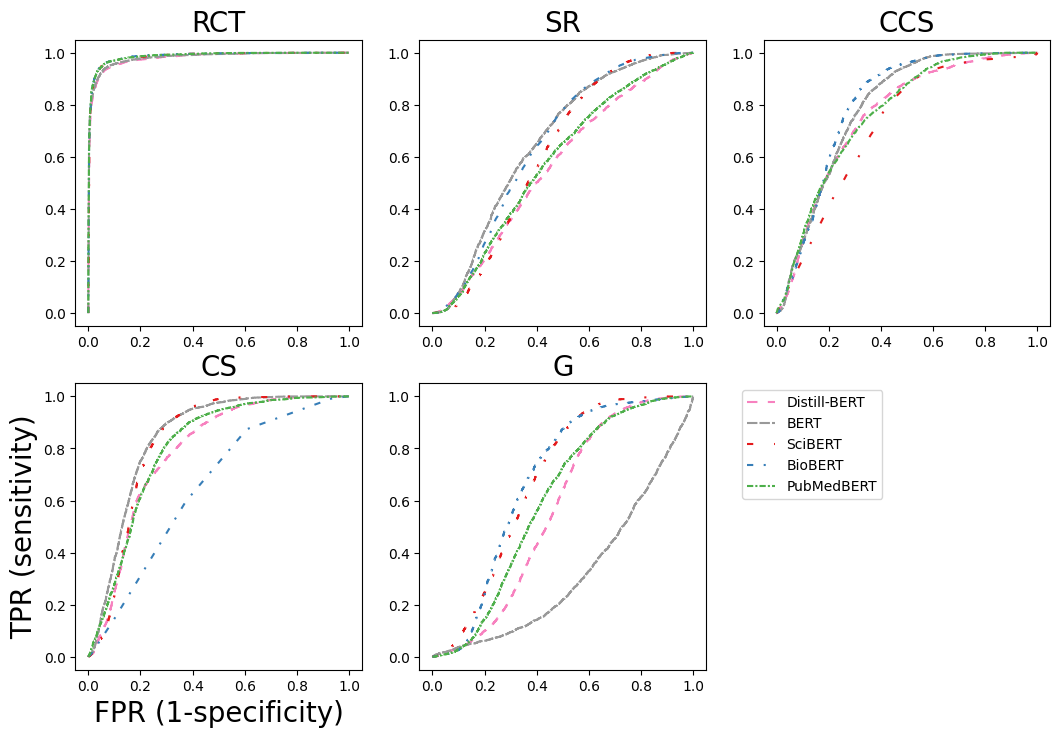

In [187]:
fig=plt.figure(figsize=(10,7))
plt.subplots_adjust(left=None, bottom=-0.1, right=1.1, top=0.8)

columns = 3
rows = 2

for i, ptype in enumerate(ptypes):
    ax = fig.add_subplot(rows, columns, i+1)
    for mtype in names_to_capital.values():
        color = capital2color[mtype]
        linestyle = capital2style[mtype]
        
        y_true = bert_outputs_labels[ptype][mtype]['labels']
        outputs = bert_outputs_labels[ptype][mtype]['outputs']
        outputs = np.concatenate(outputs)
        y_score = get_scores(outputs)
        fpr, tpr, thresholds = metrics.roc_curve(y_true, y_score)
        ax.plot(fpr, tpr, label = mtype, color=color, linestyle=linestyle)
        ax.set_title(ptype2names[ptype], fontsize=20)
#             axs[i, j].legend()
    if i == 3:
        ax.set_xlabel("FPR (1-specificity)", fontsize=20)
        ax.set_ylabel("TPR (sensitivity)", fontsize=20)
    elif i == 4:
        ax.legend(fontsize=10, bbox_to_anchor=(1.1, 1))
plt.savefig(f"figures/auc_curves_bert_group.pdf")

In [186]:
mtype

'distilbert-base-uncased'